**1. Introduction**

In [1]:

from torchvision import datasets
import torchvision.transforms as transforms

from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)


cuda


2. Install KaggleHub



In [80]:

# Install KaggleHub

!pip install -q kagglehub

print("KaggleHub installed successfully!")


KaggleHub installed successfully!


3. Download **dataset**

In [2]:

import kagglehub

path = kagglehub.dataset_download("alessiocorrado99/animals10")

print("Dataset downloaded successfully!")
print("Dataset Path:", path)


Using Colab cache for faster access to the 'animals10' dataset.
Dataset downloaded successfully!
Dataset Path: /kaggle/input/animals10


**4.  Check dataset Loading and Exploration**

In [3]:

# Check dataset folder structure


import os

for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)
    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")



animals10/
  raw-img/
    cavallo/
    pecora/
    elefante/
    gatto/
    scoiattolo/
    gallina/
    ragno/
    mucca/
    cane/
    farfalla/


**5. Dataset Description**

In [15]:
import os

dataset_path = os.path.join(path, "raw-img")

print("Animals-10 Dataset Summary")

for class_name in sorted(os.listdir(dataset_path)):
    class_path = os.path.join(dataset_path, class_name)

    if os.path.isdir(class_path):
        print(class_name, ":", len(os.listdir(class_path)), "images")

Animals-10 Dataset Summary
cane : 4863 images
cavallo : 2623 images
elefante : 1446 images
farfalla : 2112 images
gallina : 3098 images
gatto : 1668 images
mucca : 1866 images
pecora : 1820 images
ragno : 4821 images
scoiattolo : 1862 images


**6. Data Preprocessing**

In [33]:

import torchvision.transforms as transforms
from torch.utils.data import random_split, Subset
from torchvision import datasets
import torch

size = 32

train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

data_folder = path + '/raw-img'

full_train_data = datasets.ImageFolder(
    data_folder,
    transform=train_transform
)

full_val_data = datasets.ImageFolder(
    data_folder,
    transform=val_transform
)

train_size = int(0.8 * len(full_train_data))
remaining_size = len(full_train_data) - train_size

train_indices, remaining_indices = random_split(
    range(len(full_train_data)),
    [train_size, remaining_size],
    generator=torch.Generator().manual_seed(42)
)

val_size = remaining_size // 2
test_size = remaining_size - val_size

val_positions, test_positions = random_split(
    range(len(remaining_indices)),
    [val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

val_original_indices = [
    remaining_indices[i] for i in val_positions.indices
]

test_original_indices = [
    remaining_indices[i] for i in test_positions.indices
]

train_data = Subset(full_train_data, train_indices.indices)
val_data = Subset(full_val_data, val_original_indices)
test_data = Subset(full_val_data, test_original_indices)

print("Dataset Loading Successful!")
print("Training Images:", len(train_data))
print("Validation Images:", len(val_data))
print("Testing Images:", len(test_data))
print("Total Images:", len(train_data) + len(val_data) + len(test_data))


Dataset Loading Successful!
Training Images: 20943
Validation Images: 2618
Testing Images: 2618
Total Images: 26179


**7. change the class name from itilan to eng**

In [35]:
class_names = {
    'cane': 'Dog',
    'cavallo': 'Horse',
    'elefante': 'Elephant',
    'farfalla': 'Butterfly',
    'gallina': 'Chicken',
    'gatto': 'Cat',
    'mucca': 'Cow',
    'pecora': 'Sheep',
    'ragno': 'Spider',
    'scoiattolo': 'Squirrel'
}

print("English Class Names:")

for italian, english in class_names.items():
    print(italian, ":", english)

English Class Names:
cane : Dog
cavallo : Horse
elefante : Elephant
farfalla : Butterfly
gallina : Chicken
gatto : Cat
mucca : Cow
pecora : Sheep
ragno : Spider
scoiattolo : Squirrel


8. Dataset Summary

In [36]:
english_class_to_idx = {
    class_names[italian]: index
    for italian, index in full_train_data.class_to_idx.items()
}

print('Dataset Summary')
print('Train Data: ', len(train_data))
print('Validation Data: ', len(val_data))
print('Test Data: ', len(test_data))
print('Classes and Indices: ', english_class_to_idx)

Dataset Summary
Train Data:  20943
Validation Data:  2618
Test Data:  2618
Classes and Indices:  {'Dog': 0, 'Horse': 1, 'Elephant': 2, 'Butterfly': 3, 'Chicken': 4, 'Cat': 5, 'Cow': 6, 'Sheep': 7, 'Spider': 8, 'Squirrel': 9}


**9. Hyperparameter Settings**

In [37]:
batch_size = 32
learning_rate = 1e-3
epoch_number = 10

print("Hyperparameters Set Successfully!")
print("Batch Size:", batch_size)
print("Learning Rate:", learning_rate)
print("Epochs:", epoch_number)

Hyperparameters Set Successfully!
Batch Size: 32
Learning Rate: 0.001
Epochs: 10


**10. DataLoader Creation**

In [38]:
trn_dl = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

val_dl = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

test_dl = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

print("Training Batches:", len(trn_dl))
print("Validation Batches:", len(val_dl))
print("Testing Batches:", len(test_dl))

Training Batches: 655
Validation Batches: 82
Testing Batches: 82


In [39]:
from torch.optim import SGD, Adam

def get_model():
    model = nn.Sequential(
        # Feature Extraction
        nn.Conv2d(3, 64, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(64, 128, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Classifier
        nn.Flatten(),
        nn.Linear(128 * 6 * 6, 256),
        nn.ReLU(),
        nn.Linear(256, 10)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)

    return model, loss_fn, optimizer

**12. CNN Model Architecture**

In [40]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []

    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())

        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)

    return np.mean(epoch_losses), np.mean(epoch_accuracies)


@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []

    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())

        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)

    return np.mean(val_losses), np.mean(val_accuracies)

**13. Model Summary**

In [41]:
from torchsummary import summary

model, loss_fn, optimizer = get_model()

summary(model, input_size=(3, 32, 32))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 30, 30]           1,792
              ReLU-2           [-1, 64, 30, 30]               0
         MaxPool2d-3           [-1, 64, 15, 15]               0
            Conv2d-4          [-1, 128, 13, 13]          73,856
              ReLU-5          [-1, 128, 13, 13]               0
         MaxPool2d-6            [-1, 128, 6, 6]               0
           Flatten-7                 [-1, 4608]               0
            Linear-8                  [-1, 256]       1,179,904
              ReLU-9                  [-1, 256]               0
           Linear-10                   [-1, 10]           2,570
Total params: 1,258,122
Trainable params: 1,258,122
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 1.39
Params size (MB): 4.80
Estimat

**14. Model Training**

In [42]:
# Training Loop

train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):

    epoch_loss, epoch_accuracy = train_one_epoch(
        trn_dl, model, loss_fn, optimizer
    )

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    v_loss, v_acc = validation(
        val_dl, model, loss_fn
    )

    val_losses.append(v_loss)
    val_accuracies.append(v_acc)

    print(
        f"Epoch [{epoch + 1}/{epoch_number}]"
        f" | Train Loss: {epoch_loss:.4f}"
        f" | Train Accuracy: {epoch_accuracy * 100:.2f}%"
        f" | Val Loss: {v_loss:.4f}"
        f" | Val Accuracy: {v_acc * 100:.2f}%"
    )

Epoch [1/10] | Train Loss: 1.8734 | Train Accuracy: 33.89% | Val Loss: 1.5833 | Val Accuracy: 45.84%
Epoch [2/10] | Train Loss: 1.5646 | Train Accuracy: 46.26% | Val Loss: 1.4374 | Val Accuracy: 52.48%
Epoch [3/10] | Train Loss: 1.4270 | Train Accuracy: 50.85% | Val Loss: 1.3923 | Val Accuracy: 51.95%
Epoch [4/10] | Train Loss: 1.3209 | Train Accuracy: 55.24% | Val Loss: 1.2531 | Val Accuracy: 57.91%
Epoch [5/10] | Train Loss: 1.2605 | Train Accuracy: 56.95% | Val Loss: 1.2058 | Val Accuracy: 59.40%
Epoch [6/10] | Train Loss: 1.1934 | Train Accuracy: 59.49% | Val Loss: 1.1916 | Val Accuracy: 58.40%
Epoch [7/10] | Train Loss: 1.1435 | Train Accuracy: 60.97% | Val Loss: 1.1174 | Val Accuracy: 62.15%
Epoch [8/10] | Train Loss: 1.1019 | Train Accuracy: 62.80% | Val Loss: 1.1259 | Val Accuracy: 60.77%
Epoch [9/10] | Train Loss: 1.0583 | Train Accuracy: 63.71% | Val Loss: 1.1081 | Val Accuracy: 62.61%
Epoch [10/10] | Train Loss: 1.0188 | Train Accuracy: 65.57% | Val Loss: 1.1235 | Val Accura

**15. Training and Validation Loss**

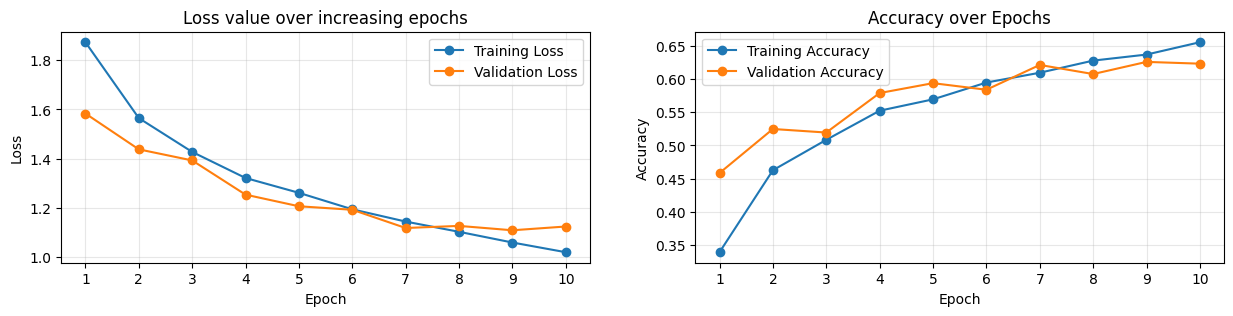

In [45]:
epochs = np.arange(epoch_number) + 1

plt.figure(figsize=(15, 3))

plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

**16. Model Evaluation on Test Dataset**

In [46]:
from sklearn.metrics import classification_report, confusion_matrix

model.eval()

test_loss = 0
correct = 0
total = 0

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_dl:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = loss_fn(outputs, labels)

        test_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_accuracy = 100 * correct / total

print("Test Loss:", test_loss / len(test_dl))
print("Test Accuracy:", test_accuracy, "%")


Test Loss: 1.1573803940924203
Test Accuracy: 61.19174942704355 %


**17. Classification Report**

In [48]:
print(classification_report(
    all_labels,
    all_predictions,
    target_names=[class_names[name] for name in full_train_data.classes],
    zero_division=0
))

              precision    recall  f1-score   support

         Dog       0.56      0.62      0.59       478
       Horse       0.53      0.75      0.62       260
    Elephant       0.63      0.45      0.53       146
   Butterfly       0.80      0.62      0.70       212
     Chicken       0.68      0.70      0.69       303
         Cat       0.46      0.31      0.37       167
         Cow       0.51      0.32      0.40       179
       Sheep       0.46      0.60      0.52       193
      Spider       0.73      0.84      0.78       477
    Squirrel       0.63      0.36      0.46       203

    accuracy                           0.61      2618
   macro avg       0.60      0.56      0.57      2618
weighted avg       0.61      0.61      0.60      2618



**18. Confusion Matrix**

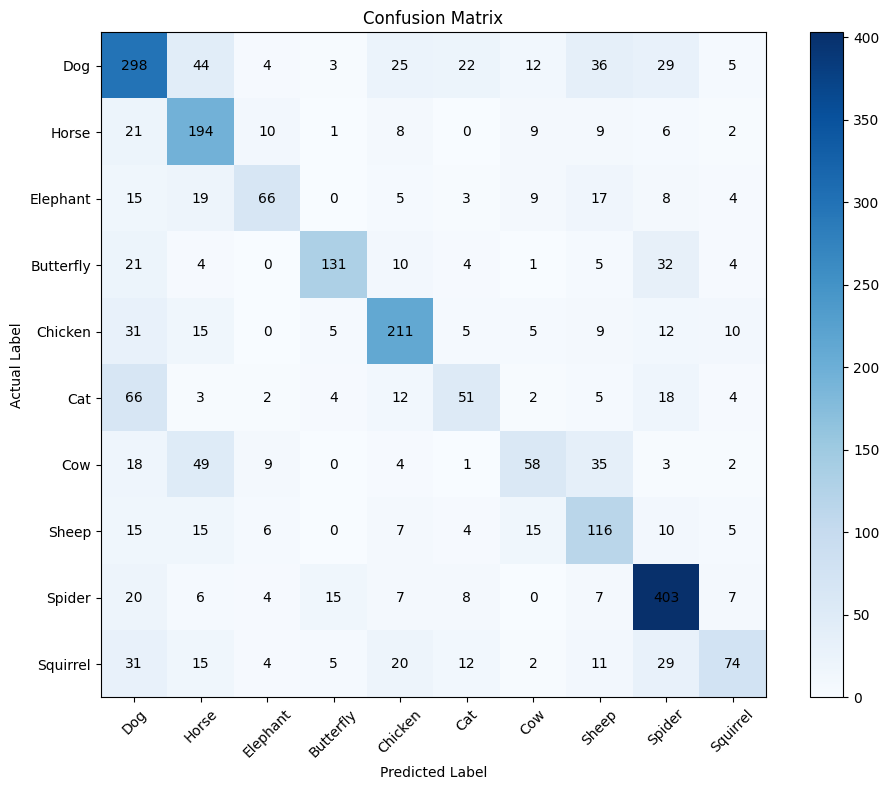

In [49]:
cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(10, 8))

plt.imshow(cm, cmap='Blues')

plt.title('Confusion Matrix')

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.xticks(range(10), [class_names[name] for name in full_train_data.classes], rotation=45)
plt.yticks(range(10), [class_names[name] for name in full_train_data.classes])

plt.colorbar()

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.tight_layout()
plt.show()

**19. Single Image Predictions**

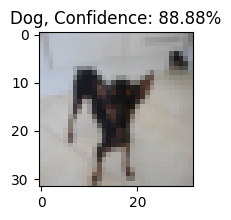

In [62]:
test_img, label = test_data[920]

img = test_img.view(-1, 3, size, size).to(device)

output = model(img)

pred = torch.exp(output) / torch.sum(torch.exp(output))

confidence, index = pred.max(-1)

plt.figure(figsize=(2, 2))

plt.imshow(test_img.view(3, size, size).permute(1, 2, 0))

plt.title(
    f'{class_names[full_train_data.classes[index.item()]]}, '
    f'Confidence: {confidence.item() * 100:.2f}%'
)

plt.show()

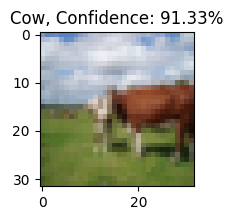

In [55]:
test_img, label = test_data[584]

img = test_img.view(-1, 3, size, size).to(device)

output = model(img)

pred = torch.exp(output) / torch.sum(torch.exp(output))

confidence, index = pred.max(-1)

plt.figure(figsize=(2, 2))

plt.imshow(test_img.view(3, size, size).permute(1, 2, 0))

plt.title(
    f'{class_names[full_train_data.classes[index.item()]]}, '
    f'Confidence: {confidence.item() * 100:.2f}%'
)

plt.show()

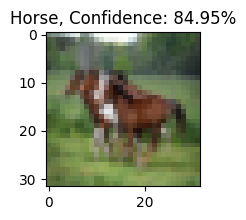

In [56]:
test_img, label = test_data[745]

img = test_img.view(-1, 3, size, size).to(device)

output = model(img)

pred = torch.exp(output) / torch.sum(torch.exp(output))

confidence, index = pred.max(-1)

plt.figure(figsize=(2, 2))

plt.imshow(test_img.view(3, size, size).permute(1, 2, 0))

plt.title(
    f'{class_names[full_train_data.classes[index.item()]]}, '
    f'Confidence: {confidence.item() * 100:.2f}%'
)

plt.show()

**20. Model Saving**

In [70]:
torch.save(model.state_dict(), 'CNN_model.pth')

print("Model Saved Successfully!")

Model Saved Successfully!


In [72]:

from google.colab import files

files.download('CNN_model.pth')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 21. Analysis & Discussion of Results

The CNN model was trained for 10 epochs using the Animals-10 dataset, which contains 10 different animal classes. During training, the training loss decreased from 1.8734 to 1.0188, while the training accuracy increased from 33.89% to 65.57%. The validation accuracy reached 62.34% in the final epoch.

On the test dataset, the model achieved **61.19% accuracy** with a test loss of **1.1574**. The weighted precision, recall, and F1-score were **0.61, 0.61, and 0.60**, respectively.

The confusion matrix and classification report show that the model performed best in classifying Spider images, achieving an F1-score of 0.78, followed by Butterfly with 0.70. However, the model showed lower performance in classifying Cat and Cow images, with F1-scores of 0.37 and 0.40, respectively. These results indicate that the CNN model learned useful image features for multi-class animal classification, but its performance can still be improved through better architecture, data augmentation, and hyperparameter tuning.

## 22. Conclusions & Future Work

In this project, a custom CNN model was developed using PyTorch to classify images of 10 different animal classes from the Animals-10 dataset. The model achieved 61.19% test accuracy after 10 epochs of training. This project demonstrates the application of Convolutional Neural Networks (CNNs) in multi-class image classification.

# In the future, model performance could be improved by increasing image resolution, using more training epochs, applying advanced data augmentation techniques, optimizing hyperparameters, and developing a deeper CNN architecture. These improvements may help achieve better classification accuracy.